In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))

import pandas as pd
import metrics
from io_utils import load_data
import viz
import analyzer
df = load_data()
health = analyzer.HealthAnalyzer(df)


In [21]:
import importlib
importlib.reload(analyzer)
importlib.reload(metrics)
importlib.reload(viz)

<module 'viz' from 'c:\\Users\\Lovisgaming\\Desktop\\ANALYS NY\\Health_Study_Analyze\\src\\viz.py'>

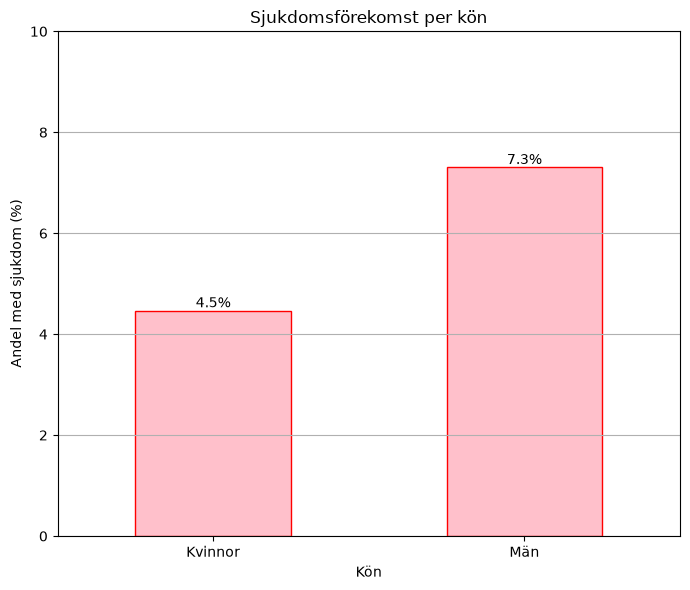

In [3]:
health.bar_disease_sex()

In [4]:
health.get_summary()

,age,weight,height,systolic_bp,cholesterol
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,73.413000,171.849250,149.178625,4.929150
std,14.501118,13.685059,9.804259,12.793360,0.848413
min,18.000000,33.700000,144.400000,106.800000,2.500000
25%,39.000000,64.800000,164.775000,140.900000,4.327500
50%,50.000000,73.200000,171.350000,149.400000,4.970000
75%,59.000000,82.600000,178.925000,157.600000,5.482500
max,90.000000,114.400000,200.400000,185.900000,7.880000


In [5]:
slope, intercept = metrics.age_bp_regression(df)

print("Lutning:", slope)
print("Intercept:", intercept)

Lutning: 0.5360255996690318
Intercept: 122.6848897043585


In [6]:
health.get_summary()

,age,weight,height,systolic_bp,cholesterol
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,49.426250,73.413000,171.849250,149.178625,4.929150
std,14.501118,13.685059,9.804259,12.793360,0.848413
min,18.000000,33.700000,144.400000,106.800000,2.500000
25%,39.000000,64.800000,164.775000,140.900000,4.327500
50%,50.000000,73.200000,171.350000,149.400000,4.970000
75%,59.000000,82.600000,178.925000,157.600000,5.482500
max,90.000000,114.400000,200.400000,185.900000,7.880000


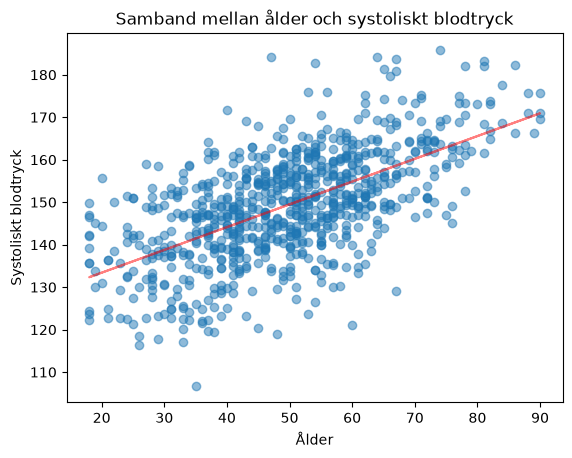

In [7]:
health.scat_age_bp()

In [8]:
disease_by_sex = metrics.disease_by_sex(df)

print(disease_by_sex)

sex
F    0.044665
M    0.073048
Name: disease, dtype: float64


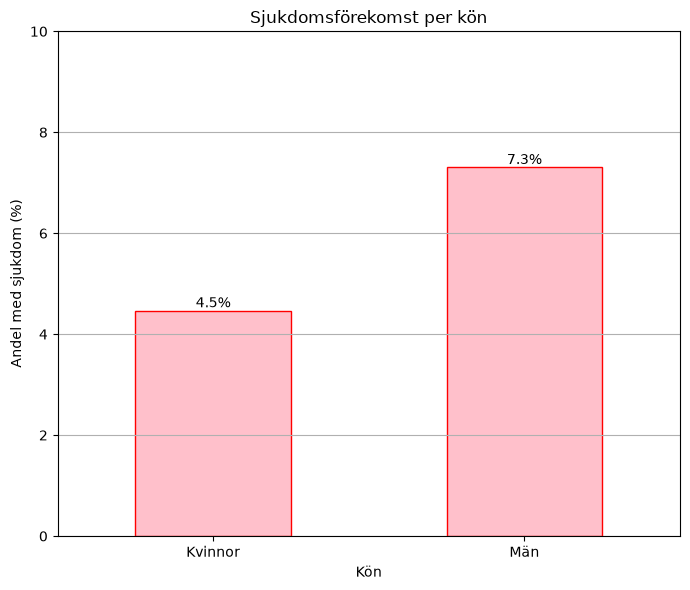

In [9]:
viz.bar_disease_sex(df)

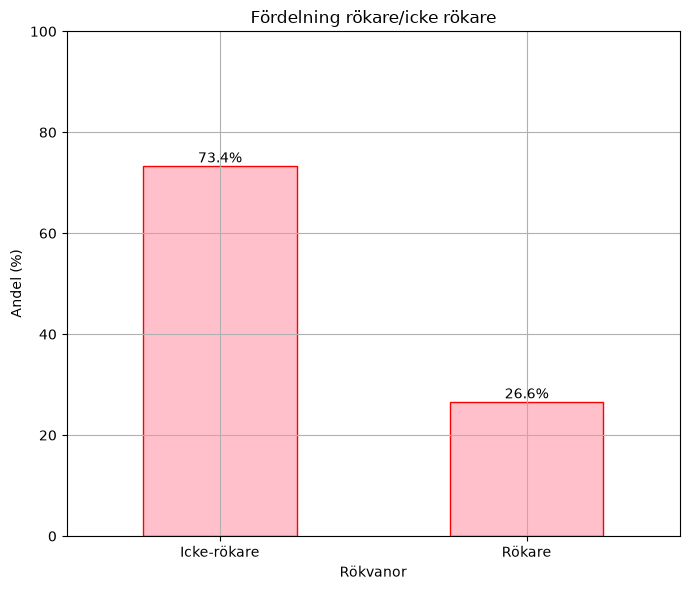

In [10]:
import matplotlib.pyplot as plt

smoker_percent = df["smoker"].value_counts(normalize=True) * 100
smoker_percent = smoker_percent.rename({
    "No": "Icke-rökare",
    "Yes": "Rökare"
})
smoker_percent.plot(
    kind="bar",
    color="pink",
    edgecolor="red",
    figsize=(7,6)
    )
plt.grid("y")
plt.title("Fördelning rökare/icke rökare")
plt.xlabel("Rökvanor")
plt.ylabel("Andel (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.bar_label(plt.gca().containers[0], fmt="%.1f%%")
plt.tight_layout()
plt.show()

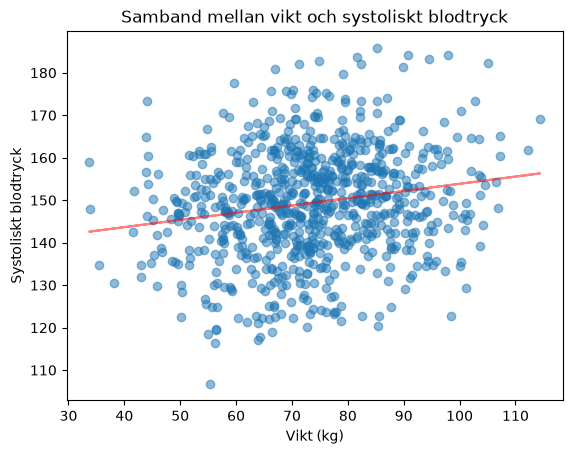

Det förväntade systoliska blodtrycket ökar med cirka 0.17 mmHg / kg.


In [12]:
viz.scat_weight_bp(df)

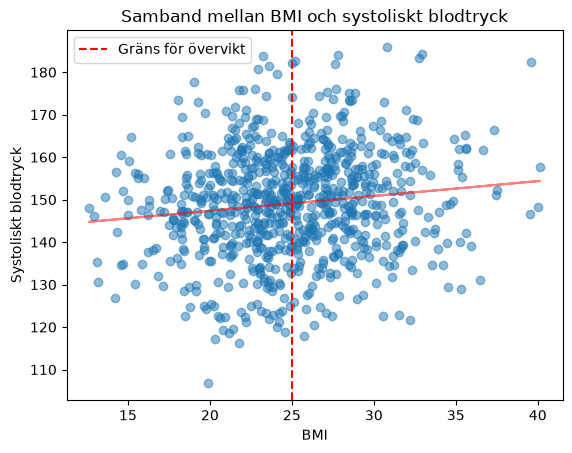

För varje ökning med 1 BMI-enhet förändras det förväntade systoliska blodtrycket med cirka 0.35 mmHg.


In [22]:
viz.scat_bmi_bp(df)